# Explainable classification of payment difficulty

**Inteligencia Artificial Explicable — Hands-on Project, Unit 2 (Phase II)**

Group: Thales S. A. Camargo, Jhon Corrales Almendariz, Joel Montes de Oca Martínez

This notebook contains the complete project. It is organised like the course labs:

1. Data and evaluation protocol
2. Decision tree (logical model)
3. Logistic regression
4. Explainable Boosting Machine (`interactions=0`)
5. Comparison of the three models (performance, global and local explanations, subgroup audit)
6. Final model and completed `test.csv`

**Protocol.** The labelled data are split once into an 80 % *training* set and a 20 % *validation* set
(stratified, seed 411). Every decision (model comparison, hyperparameters, feature transformation and
classification threshold) is taken with the same five stratified folds of the training set. The validation set
is only used at the end, to confirm the CV results and to pick instances for local explanations.

## Install and load libraries

In [1]:
# Install InterpretML (already available locally; needed in Google Colab).
# To run in Colab, first upload train.csv and test.csv to the session's working directory (Files panel);
# the notebook reads them from there. Locally, it reads them from ../data.
%pip install -q interpret

Note: you may need to restart the kernel to use updated packages.


In [2]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    confusion_matrix,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text, plot_tree, _tree

from interpret import set_visualize_provider, show
from interpret.provider import InlineProvider
from interpret.data import ClassHistogram
from interpret.glassbox import ClassificationTree, ExplainableBoostingClassifier, LogisticRegression

set_visualize_provider(InlineProvider())
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

seed = 411
n_jobs = 2  # parallel workers for the grid searches (Colab has two cores)

# One colour per model, used in every figure.
model_colors = {"Decision tree": "#2a78d6", "Logistic regression": "#eb6834", "EBM": "#1baf7a"}
reference_color = "#8a8984"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 220,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6, "axes.axisbelow": True,
    # Figures are drawn close to their printed width in the report, so these sizes stay legible.
    "font.size": 9, "axes.titlesize": 9, "axes.labelsize": 9,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
})

## 1. Data

25,000 labelled and 5,000 unlabelled credit-card clients, 15 predictors and the binary target
`payment_difficulty_next_month`.

In [3]:
data_dir = Path("../data") if Path("../data/train.csv").exists() else Path(".")
fig_dir = Path("../report/figures") if Path("../report").exists() else Path("figures")
fig_dir.mkdir(parents=True, exist_ok=True)


def save_figure(fig, name):
    fig.savefig(fig_dir / f"{name}.pdf", bbox_inches="tight")
    fig.savefig(fig_dir / f"{name}.png", bbox_inches="tight")


target = "payment_difficulty_next_month"
categorical = ["sex", "education", "marital_status", "repayment_assistance_plan"]
money = ["credit_limit", "average_bill_6m", "bill_change_sep_to_apr", "total_payment_6m"]

train = pd.read_csv(data_dir / "train.csv")
# test.csv is completed at the end of this notebook; drop the prediction column when re-running.
test = pd.read_csv(data_dir / "test.csv").drop(columns=["predicted_class"], errors="ignore")
train[categorical] = train[categorical].astype(str)
test[categorical] = test[categorical].astype(str)

X = train.drop(columns=["row_id", target])
y = train[target].astype(int)
X_test = test[X.columns]
numeric = [column for column in X.columns if column not in categorical]

print(f"Labelled rows: {len(train):,}; test rows: {len(test):,}; predictors: {X.shape[1]}")
print(f"Missing values in train/test: {int(train.isna().sum().sum())}/{int(test.isna().sum().sum())}")
print(f"Positive rate: {y.mean():.3f}  ->  majority-class accuracy {1 - y.mean():.3f}")
X.describe().T.round(2)

Labelled rows: 25,000; test rows: 5,000; predictors: 15
Missing values in train/test: 0/0
Positive rate: 0.212  ->  majority-class accuracy 0.788


,count,mean,std,min,25%,50%,75%,max
credit_limit,25000.0,167740.95,129975.98,10000.0,50000.00,140000.00,240000.00,1000000.0
age,25000.0,35.50,9.24,21.0,28.00,34.00,41.00,79.0
latest_repayment_status,25000.0,-0.02,1.12,-2.0,-1.00,0.00,0.00,8.0
maximum_repayment_delay_6m,25000.0,0.68,1.07,0.0,0.00,0.00,2.00,8.0
delayed_months_6m,25000.0,0.83,1.55,0.0,0.00,0.00,1.00,6.0
average_bill_6m,25000.0,44910.44,63267.26,-56000.0,4700.00,21000.00,57100.00,877300.0
bill_change_sep_to_apr,25000.0,12389.51,44068.85,-403600.0,-3000.00,900.00,19900.00,708300.0
total_payment_6m,25000.0,31635.05,57337.82,0.0,6700.00,14400.00,33700.00,2314200.0
payment_to_bill_ratio_6m,25000.0,0.37,0.59,0.0,0.04,0.09,0.60,5.0
zero_payment_months_6m,25000.0,1.23,1.72,0.0,0.00,0.00,2.00,6.0


### Explore the dataset

About 21 % of clients have payment difficulty, so the classes are imbalanced: always predicting "no difficulty"
already gives 78.8 % accuracy.

In [4]:
hist = ClassHistogram().explain_data(X, y, name="All labelled data")
show(hist)

The empirical difficulty rate per value of the main behavioural variables already shows non-linear patterns:
`latest_repayment_status = -1` has a lower rate than `-2`, and six zero-payment months more than double the risk
of five. The data dictionary warns against assuming linear effects for these summaries.

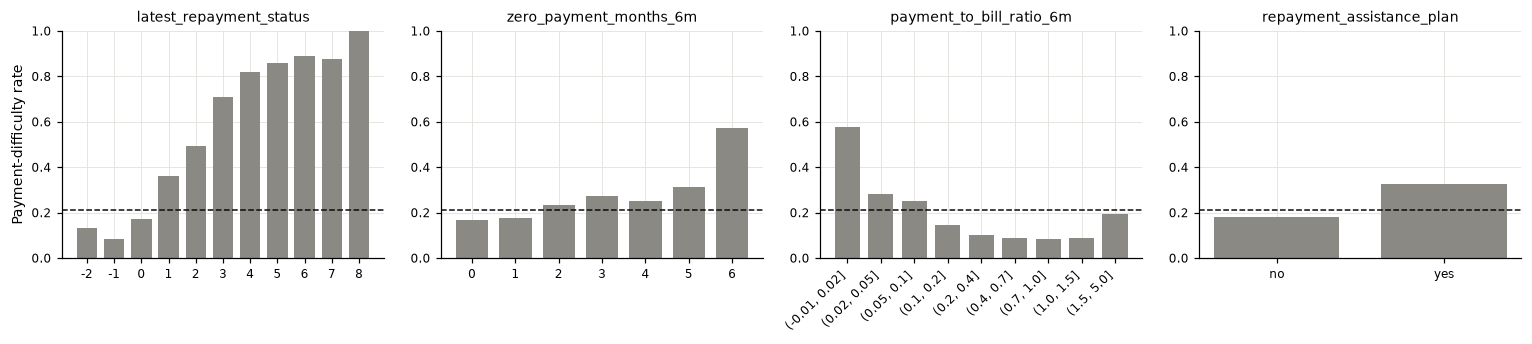

In [5]:
eda_specs = [
    ("latest_repayment_status", None),
    ("zero_payment_months_6m", None),
    ("payment_to_bill_ratio_6m", [-0.01, 0.02, 0.05, 0.1, 0.2, 0.4, 0.7, 1.0, 1.5, 5.0]),
    ("repayment_assistance_plan", None),
]
fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (column, bins) in zip(axes, eda_specs):
    key = pd.cut(train[column], bins) if bins is not None else train[column]
    rates = train.groupby(key, observed=True)[target].mean()
    ax.bar(range(len(rates)), rates, color=reference_color, width=0.75)
    ax.axhline(y.mean(), color="#0b0b0b", lw=1, ls="--")
    ax.set_xticks(range(len(rates)), [str(i) for i in rates.index], rotation=45 if bins else 0,
                  ha="right" if bins else "center")
    ax.set_title(column)
    ax.set_ylim(0, 1)
axes[0].set_ylabel("Payment-difficulty rate")
fig.tight_layout()
plt.show()

### Evaluation protocol

* 80/20 stratified split into training and validation sets.
* The same five stratified folds of the training set are used for every model and every decision.
* Hyperparameters are chosen by **CV ROC AUC**, which does not depend on the classification threshold.
* Class imbalance is handled by **choosing the threshold with CV** instead of class weights, so all three models
  keep comparable, approximately calibrated probabilities. On the pooled out-of-fold predictions we pick
  `t_acc` (maximizes accuracy; used for the submission, which is graded on accuracy) and `t_bal` (maximizes
  balanced accuracy; our analysis operating point).
* For the tree and logistic regression we use the **one-standard-error rule**: among the settings within one
  standard error of the best CV AUC, keep the simplest one.

In [6]:
X_train, X_validation, y_train, y_validation = train_test_split(X, y, test_size=0.2, stratify=y, random_state=seed)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=seed).split(X_train, y_train))
threshold_grid = np.round(np.arange(0.05, 0.951, 0.01), 2)
print(f"Training rows:   {len(X_train):,} (positive rate {y_train.mean():.3f})")
print(f"Validation rows: {len(X_validation):,} (positive rate {y_validation.mean():.3f})")


def simplest_within_one_se(complexity):
    """Refit rule for GridSearchCV: the simplest setting within one standard error of the best."""
    def select(cv_results):
        mean = np.asarray(cv_results["mean_test_score"])
        se = np.asarray(cv_results["std_test_score"]) / np.sqrt(len(folds))
        best = int(np.argmax(mean))
        eligible = np.flatnonzero(mean >= mean[best] - se[best])
        return int(min(eligible, key=lambda i: complexity(cv_results["params"][i])))
    return select


def out_of_fold(model):
    """Fit the model on each CV training fold and predict the left-out fold."""
    probabilities = np.zeros(len(y_train))
    fold_id = np.zeros(len(y_train), dtype=int)
    for fold, (fit_index, left_out_index) in enumerate(folds):
        fitted = clone(model).fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
        probabilities[left_out_index] = fitted.predict_proba(X_train.iloc[left_out_index])[:, 1]
        fold_id[left_out_index] = fold
    return probabilities, fold_id


def best_threshold(probabilities, metric):
    scores = [metric(y_train, (probabilities >= t).astype(int)) for t in threshold_grid]
    return float(threshold_grid[int(np.argmax(scores))])


def classification_metrics(y_true, probabilities, t_acc, t_bal):
    flagged = (probabilities >= t_bal).astype(int)
    return {
        "auc": roc_auc_score(y_true, probabilities) if probabilities.std() > 0 else 0.5,
        "brier": brier_score_loss(y_true, probabilities),
        "accuracy": accuracy_score(y_true, (probabilities >= t_acc).astype(int)),
        "balanced_accuracy": balanced_accuracy_score(y_true, flagged),
        "recall_1": recall_score(y_true, flagged, pos_label=1, zero_division=0),
        "recall_0": recall_score(y_true, flagged, pos_label=0, zero_division=0),
    }


# Filled in by each model section and used in the comparison.
models, oof, thresholds, fold_metrics = {}, {}, {}, []


def evaluate_with_cv(name, model, choose_thresholds=True):
    """Out-of-fold probabilities, CV-chosen thresholds and per-fold metrics for one model."""
    probabilities, fold_id = out_of_fold(model)
    oof[name] = probabilities
    thresholds[name] = ({"t_acc": best_threshold(probabilities, accuracy_score),
                         "t_bal": best_threshold(probabilities, balanced_accuracy_score)}
                        if choose_thresholds else {"t_acc": 0.5, "t_bal": 0.5})
    for fold in range(len(folds)):
        mask = fold_id == fold
        fold_metrics.append({"model": name, "fold": fold,
                             **classification_metrics(y_train.to_numpy()[mask], probabilities[mask],
                                                      **thresholds[name])})
    summary = pd.DataFrame([m for m in fold_metrics if m["model"] == name]).drop(columns=["model", "fold"])
    print(f"{name}: t_acc = {thresholds[name]['t_acc']:.2f}, t_bal = {thresholds[name]['t_bal']:.2f}")
    return summary.agg(["mean", "std"]).round(3)


def original_feature(encoded_name):
    """Map an encoded column such as 'education_university' back to 'education'."""
    for column in categorical:
        if encoded_name.startswith(column + "_"):
            return column
    return encoded_name


def logit(probability):
    probability = np.clip(probability, 1e-3, 1 - 1e-3)
    return np.log(probability / (1 - probability))


def pretty(name):
    return name.replace("_6m", "").replace("_", " ")

Training rows:   20,000 (positive rate 0.212)
Validation rows: 5,000 (positive rate 0.212)


## 2. Decision tree

Categorical predictors are one-hot encoded; numerical predictors keep their original units (splits do not need
scaling and raw thresholds are easier to read).

### Train: choose depth and leaf size with CV

We search `max_depth` and `min_samples_leaf`, the two parameters that control how many rules a reader has to
follow. `GridSearchCV` needs scikit-learn's `DecisionTreeClassifier`; the course's `ClassificationTree` is a
wrapper around the same class, and we refit it with the selected settings below for the InterpretML views.

In [7]:
tree_encoder = ColumnTransformer(
    [("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical)],
    remainder="passthrough", verbose_feature_names_out=False,
)
tree_pipeline = Pipeline([("prep", tree_encoder), ("model", DecisionTreeClassifier(random_state=seed))])
tree_grid = {"model__max_depth": [2, 3, 4, 5, 6, 7, 8, 10], "model__min_samples_leaf": [25, 50, 100, 200, 400]}
tree_search = GridSearchCV(
    tree_pipeline, tree_grid, scoring="roc_auc", cv=folds, n_jobs=n_jobs,
    refit=simplest_within_one_se(lambda p: (p["model__max_depth"], -p["model__min_samples_leaf"])),
).fit(X_train, y_train)
tree_model = tree_search.best_estimator_
tree_params = tree_search.cv_results_["params"][tree_search.best_index_]
models["Decision tree"] = tree_model

tree_results = pd.DataFrame(tree_search.cv_results_)
print("Selected:", tree_params, f"CV AUC {tree_results.loc[tree_search.best_index_, 'mean_test_score']:.4f}")
tree_results[["param_model__max_depth", "param_model__min_samples_leaf", "mean_test_score", "std_test_score"]] \
    .sort_values("mean_test_score", ascending=False).head(8).round(4)

Selected: {'model__max_depth': 5, 'model__min_samples_leaf': 400} CV AUC 0.7524


,param_model__max_depth,param_model__min_samples_leaf,mean_test_score,std_test_score
15,5,25,0.7553,0.0091
20,6,25,0.7553,0.0099
27,7,100,0.7552,0.0090
24,6,400,0.7549,0.0085
23,6,200,0.7548,0.0076
16,5,50,0.7546,0.0087
22,6,100,0.7544,0.0086
21,6,50,0.7541,0.0083


Several settings are statistically tied (depth 5–7). The one-standard-error rule keeps depth 5 with leaves of at
least 400 clients, which has about half as many leaves as the best-scoring tree.

### Global explanation

Refit the selected settings with InterpretML's `ClassificationTree` (the same tree) and inspect it.

In [8]:
X_train_tree = tree_model.named_steps["prep"].transform(X_train)
tree_features = list(tree_model.named_steps["prep"].get_feature_names_out())
X_train_tree = pd.DataFrame(X_train_tree, columns=tree_features, index=X_train.index)

tree = ClassificationTree(max_depth=tree_params["model__max_depth"],
                          min_samples_leaf=tree_params["model__min_samples_leaf"], random_state=seed)
tree.fit(X_train_tree, y_train)
assert np.array_equal(tree.predict_proba(X_train_tree), tree_model.predict_proba(X_train))  # identical tree

tree_global = tree.explain_global(name="Decision tree")
show(tree_global)

Depth 5, 17 leaves


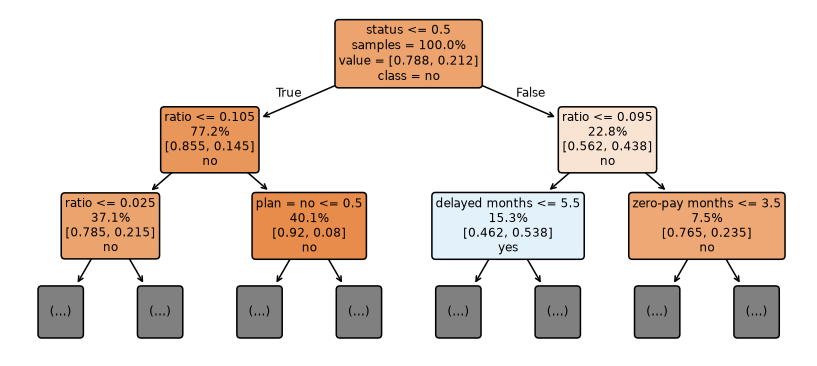

In [9]:
tree_sk = tree._model()
print(f"Depth {tree_sk.get_depth()}, {tree_sk.get_n_leaves()} leaves")
short_names = {
    "latest_repayment_status": "status", "payment_to_bill_ratio_6m": "ratio",
    "delayed_months_6m": "delayed months", "zero_payment_months_6m": "zero-pay months",
    "repayment_assistance_plan_no": "plan = no", "repayment_assistance_plan_yes": "plan = yes",
}
fig, ax = plt.subplots(figsize=(7.5, 3.4))
plot_tree(tree_sk, feature_names=[short_names.get(f, f) for f in tree_features], class_names=["no", "yes"],
          filled=True, rounded=True, proportion=True, impurity=False, max_depth=2, label="root", precision=3,
          fontsize=8, ax=ax)
fig.tight_layout()
save_figure(fig, "tree_top_levels")
plt.show()

Feature importance (normalized impurity reduction). Only 7 of the 15 variables are used, and the root split on
the latest repayment status plus the payment-to-bill ratio give 85 % of the importance. A variable that is not
used is not necessarily uninformative: it may simply be correlated with one the tree already uses.

In [10]:
tree_importance = (pd.Series(tree_sk.feature_importances_, index=tree_features)
                   .groupby(original_feature).sum().sort_values(ascending=False))
tree_importance.round(3).to_frame("impurity_importance")

,impurity_importance
latest_repayment_status,0.514
payment_to_bill_ratio_6m,0.336
delayed_months_6m,0.054
zero_payment_months_6m,0.038
repayment_assistance_plan,0.030
age,0.022
bill_change_sep_to_apr,0.005
education,0.000
credit_limit,0.000
average_bill_6m,0.000


### Evaluate

Out-of-fold predictions on the five folds give the CV metrics and the two thresholds.

In [11]:
evaluate_with_cv("Decision tree", tree_model)

Decision tree: t_acc = 0.49, t_bal = 0.18


,auc,brier,accuracy,balanced_accuracy,recall_1,recall_0
mean,0.752,0.139,0.812,0.692,0.650,0.735
std,0.011,0.003,0.005,0.009,0.012,0.019


**Complexity versus performance.** CV AUC of the best tree for each depth: AUC stops improving after depth 5,
so deeper trees only add leaves.

In [12]:
by_depth = (tree_results.sort_values("mean_test_score", ascending=False)
            .groupby("param_model__max_depth").head(1).sort_values("param_model__max_depth"))
leaves_by_depth = {}
for _, row in by_depth.iterrows():
    depth = int(row["param_model__max_depth"])
    fitted = clone(tree_pipeline).set_params(model__max_depth=depth,
                                             model__min_samples_leaf=int(row["param_model__min_samples_leaf"]))
    leaves_by_depth[depth] = fitted.fit(X_train, y_train).named_steps["model"].get_n_leaves()
by_depth.assign(leaves=list(leaves_by_depth.values()))[
    ["param_model__max_depth", "param_model__min_samples_leaf", "leaves", "mean_test_score"]].round(4)

,param_model__max_depth,param_model__min_samples_leaf,leaves,mean_test_score
4,2,400,4,0.7247
5,3,25,8,0.7378
10,4,25,16,0.7489
15,5,25,32,0.7553
20,6,25,57,0.7553
27,7,100,55,0.7552
32,8,100,69,0.7539
38,10,200,58,0.7532


### Extract rules

The rules as text, and then as logical implications with the lab's `get_rules` function (code from
<https://mljar.com/blog/extract-rules-decision-tree/>). We added an optional `stop_nodes` argument so the same
function can print a collapsed tree (next cell).

In [13]:
print(export_text(tree_sk, feature_names=tree_features))

|--- latest_repayment_status <= 0.50
|   |--- payment_to_bill_ratio_6m <= 0.11
|   |   |--- payment_to_bill_ratio_6m <= 0.02
|   |   |   |--- class: 0
|   |   |--- payment_to_bill_ratio_6m >  0.02
|   |   |   |--- age <= 24.50
|   |   |   |   |--- class: 0
|   |   |   |--- age >  24.50
|   |   |   |   |--- repayment_assistance_plan_no <= 0.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- repayment_assistance_plan_no >  0.50
|   |   |   |   |   |--- class: 0
|   |--- payment_to_bill_ratio_6m >  0.11
|   |   |--- repayment_assistance_plan_no <= 0.50
|   |   |   |--- payment_to_bill_ratio_6m <= 0.41
|   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m >  0.41
|   |   |   |   |--- class: 0
|   |   |--- repayment_assistance_plan_no >  0.50
|   |   |   |--- payment_to_bill_ratio_6m <= 1.20
|   |   |   |   |--- age <= 24.50
|   |   |   |   |   |--- class: 0
|   |   |   |   |--- age >  24.50
|   |   |   |   |   |--- class: 0
|   |   |   |--- payment_to_bill_ratio_6m

In [14]:
def get_rules(tree, feature_names, class_names, stop_nodes=()):
    tree_ = tree.tree_
    feature_name = [
        feature_names[i] if i != _tree.TREE_UNDEFINED else "undefined!"
        for i in tree_.feature
    ]
    paths = []
    path = []

    def recurse(node, path, paths):
        if tree_.feature[node] != _tree.TREE_UNDEFINED and node not in stop_nodes:
            name = feature_name[node]
            threshold = tree_.threshold[node]
            p1, p2 = list(path), list(path)
            p1 += [f"({name} <= {np.round(threshold, 3)})"]
            recurse(tree_.children_left[node], p1, paths)
            p2 += [f"({name} > {np.round(threshold, 3)})"]
            recurse(tree_.children_right[node], p2, paths)
        else:
            path += [(tree_.value[node], tree_.n_node_samples[node], node)]
            paths += [path]

    recurse(0, path, paths)

    # sort by samples count
    samples_count = [p[-1][1] for p in paths]
    ii = list(np.argsort(samples_count))
    paths = [paths[i] for i in reversed(ii)]

    rules = []
    for path in paths:
        rule = "if "
        for p in path[:-1]:
            if rule != "if ":
                rule += " and "
            rule += str(p)
        rule += " then "
        classes = path[-1][0][0]
        l = np.argmax(classes)
        rule += f"class: {class_names[l]} (proba: {np.round(100.0*classes[l]/np.sum(classes),2)}%)"
        rule += f" | based on {path[-1][1]:,} samples"
        rules += [rule]
    return rules


for r in get_rules(tree_sk, tree_features, ["no", "yes"]):
    print(r)

if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m > 0.105) and (repayment_assistance_plan_no > 0.5) and (payment_to_bill_ratio_6m <= 1.195) and (age > 24.5) then class: no (proba: 93.76%) | based on 5,709 samples
if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (payment_to_bill_ratio_6m > 0.025) and (age > 24.5) and (repayment_assistance_plan_no > 0.5) then class: no (proba: 83.39%) | based on 4,979 samples
if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (payment_to_bill_ratio_6m > 0.025) and (age > 24.5) and (repayment_assistance_plan_no <= 0.5) then class: no (proba: 74.09%) | based on 1,177 samples
if (latest_repayment_status > 0.5) and (payment_to_bill_ratio_6m <= 0.095) and (delayed_months_6m <= 5.5) and (zero_payment_months_6m <= 2.5) and (repayment_assistance_plan_no > 0.5) then class: no (proba: 63.08%) | based on 1,013 samples
if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m > 0.105

### Could the rules be made more compact?

`get_rules` labels each leaf with its majority class, i.e. threshold 0.5. At our operating threshold
`t_bal`, a leaf predicts difficulty when its share of positives is at least `t_bal`. Whenever all leaves below a
node predict the same class, the splits under that node never change a decision, so the node can become a single
rule. This shortens the tree to an unordered rule set (*predict difficulty if any rule fires*) without changing a
single prediction.

In [15]:
t_bal_tree = thresholds["Decision tree"]["t_bal"]
node_risk = tree_sk.tree_.value[:, 0, 1] / tree_sk.tree_.value[:, 0, :].sum(axis=1)


def uniform_class(node):
    """Class predicted by every leaf below `node` at t_bal, or None if the leaves disagree."""
    left, right = tree_sk.tree_.children_left[node], tree_sk.tree_.children_right[node]
    if left == -1:
        return int(node_risk[node] >= t_bal_tree)
    left_class, right_class = uniform_class(left), uniform_class(right)
    return left_class if left_class is not None and left_class == right_class else None


def collapsed_nodes(node=0):
    if uniform_class(node) is not None:
        return [node]
    return (collapsed_nodes(tree_sk.tree_.children_left[node])
            + collapsed_nodes(tree_sk.tree_.children_right[node]))


stop_nodes = set(collapsed_nodes())
collapsed_rules = get_rules(tree_sk, tree_features, ["no", "yes"], stop_nodes=stop_nodes)
train_path = tree_sk.decision_path(X_train_tree.to_numpy())
rule_table = pd.DataFrame({
    "node": sorted(stop_nodes, key=lambda n: -node_risk[n]),
})
rule_table["risk"] = node_risk[rule_table["node"]]
rule_table["predicts_difficulty"] = [bool(uniform_class(n)) for n in rule_table["node"]]
rule_table["coverage"] = [train_path[:, n].toarray().mean() for n in rule_table["node"]]
rule_table["positives_covered"] = [int(y_train.to_numpy()[train_path[:, n].toarray().ravel() == 1].sum())
                                   for n in rule_table["node"]]
print(f"{tree_sk.get_n_leaves()} leaves collapse into {len(stop_nodes)} rules, "
      f"{int(rule_table['predicts_difficulty'].sum())} of which predict difficulty (t_bal = {t_bal_tree:.2f}).\n")
for r in collapsed_rules:
    print(r)
rule_table.round(3)

17 leaves collapse into 9 rules, 6 of which predict difficulty (t_bal = 0.18).

if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m > 0.105) then class: no (proba: 91.97%) | based on 8,018 samples
if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (payment_to_bill_ratio_6m > 0.025) and (age > 24.5) and (repayment_assistance_plan_no > 0.5) then class: no (proba: 83.39%) | based on 4,979 samples
if (latest_repayment_status > 0.5) and (payment_to_bill_ratio_6m <= 0.095) then class: yes (proba: 53.8%) | based on 3,063 samples
if (latest_repayment_status <= 0.5) and (payment_to_bill_ratio_6m <= 0.105) and (payment_to_bill_ratio_6m > 0.025) and (age > 24.5) and (repayment_assistance_plan_no <= 0.5) then class: no (proba: 74.09%) | based on 1,177 samples
if (latest_repayment_status > 0.5) and (payment_to_bill_ratio_6m > 0.095) and (zero_payment_months_6m <= 3.5) and (payment_to_bill_ratio_6m > 0.315) then class: no (proba: 84.57%) | based on 700 samp

,node,risk,predicts_difficulty,coverage,positives_covered
0,19,0.538,True,0.153,1648
1,3,0.426,True,0.029,243
2,32,0.330,True,0.020,133
3,5,0.322,True,0.034,221
4,30,0.281,True,0.020,113
5,7,0.259,True,0.059,305
6,8,0.166,False,0.249,827
7,31,0.154,False,0.035,108
8,9,0.080,False,0.401,644


How much does each rule add? Rules that predict difficulty are added in order of decreasing risk.

In [16]:
positive_nodes = rule_table.loc[rule_table["predicts_difficulty"], "node"].to_numpy()
coverage = []
for k in range(1, len(positive_nodes) + 1):
    fired = (np.asarray(train_path[:, positive_nodes[:k]].sum(axis=1)).ravel() > 0).astype(int)
    coverage.append({"rules": k, "balanced_accuracy": balanced_accuracy_score(y_train, fired),
                     "recall_1": recall_score(y_train, fired), "flagged_share": fired.mean()})
pd.DataFrame(coverage).round(3)

,rules,balanced_accuracy,recall_1,flagged_share
0,1,0.649,0.388,0.153
1,2,0.668,0.446,0.182
2,3,0.675,0.477,0.202
3,4,0.686,0.529,0.236
4,5,0.690,0.556,0.256
5,6,0.698,0.628,0.315


**Observations.**
* Clients behind on payments (`status >= 1`) who paid at most ~10 % of their bills form the main high-risk group:
  one rule covering 15 % of clients and 39 % of all difficulties.
* The 17 leaves become 9 rules, only 6 of which predict difficulty.
* The tree outputs only 17 distinct probabilities, so its ranking (AUC) is coarser than the other models.

## 3. Logistic regression

### Transform categoricals and scale

As in the logistic-regression lab: numerical predictors are standardized (so coefficients are comparable, in
log-odds per standard deviation) and categoricals use drop-first one-hot coding (reference categories: female,
graduate school, married, no plan). The four monetary variables are very right-skewed, so whether to apply a
signed `log1p` to them is one more option in the CV grid. The transformations are inside a `Pipeline`, so they
are re-fitted on each training fold and nothing leaks from the left-out folds.

### Train: choose C and the transformation with CV

In [17]:
def signed_log1p(values):
    return np.sign(values) * np.log1p(np.abs(values))


logit_encoder = ColumnTransformer(
    [
        ("money", Pipeline([("log", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")),
                            ("scale", StandardScaler())]), money),
        ("num", StandardScaler(), [c for c in numeric if c not in money]),
        ("cat", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False), categorical),
    ],
    verbose_feature_names_out=False,
)
logit_pipeline = Pipeline([("prep", logit_encoder), ("model", SkLogisticRegression(max_iter=5000))])
logit_grid = {
    "prep__money__log": ["passthrough", FunctionTransformer(signed_log1p, feature_names_out="one-to-one")],
    "model__C": [0.001, 0.003, 0.01, 0.03, 0.1, 0.3, 1, 10, 100],
}
logit_search = GridSearchCV(
    logit_pipeline, logit_grid, scoring="roc_auc", cv=folds, n_jobs=n_jobs,
    refit=simplest_within_one_se(lambda p: p["model__C"]),  # smaller C = stronger regularization = simpler
).fit(X_train, y_train)
logit_model = logit_search.best_estimator_
logit_params = logit_search.cv_results_["params"][logit_search.best_index_]
models["Logistic regression"] = logit_model

logit_results = pd.DataFrame(logit_search.cv_results_)
logit_results["log_money"] = logit_results["param_prep__money__log"].astype(str) != "passthrough"
print(f"Selected: C = {logit_params['model__C']}, "
      f"log of monetary variables: {logit_params['prep__money__log'] != 'passthrough'}")
logit_results.pivot_table(index="param_model__C", columns="log_money", values="mean_test_score").round(4)

Selected: C = 0.01, log of monetary variables: True


log_money,False,True
param_model__C,,
0.001,0.7427,0.7524
0.003,0.7475,0.7584
0.010,0.7495,0.7614
0.030,0.7499,0.7621
0.100,0.7499,0.7622
0.300,0.7498,0.7621
1.000,0.7497,0.7621
10.000,0.7497,0.7620
100.000,0.7497,0.7620


The log transform improves CV AUC for every `C` (about +0.012). The best AUC is at `C = 0.1`; the
one-standard-error rule picks the more regularized `C = 0.01`.

### Global explanation

Refit with InterpretML's `LogisticRegression` wrapper on the transformed data (same model) to use its views.

In [18]:
logit_features = list(logit_model.named_steps["prep"].get_feature_names_out())
X_train_logit = pd.DataFrame(logit_model.named_steps["prep"].transform(X_train), columns=logit_features,
                           index=X_train.index)
linear = LogisticRegression(C=logit_params["model__C"], max_iter=5000)
linear.fit(X_train_logit, y_train)
assert np.allclose(linear.sk_model_.coef_, logit_model.named_steps["model"].coef_)  # identical model

linear_global = linear.explain_global(name="Logistic regression")
show(linear_global)

Coefficients with their range over the five CV fits (stability), and odds ratios.

Intercept: -1.629


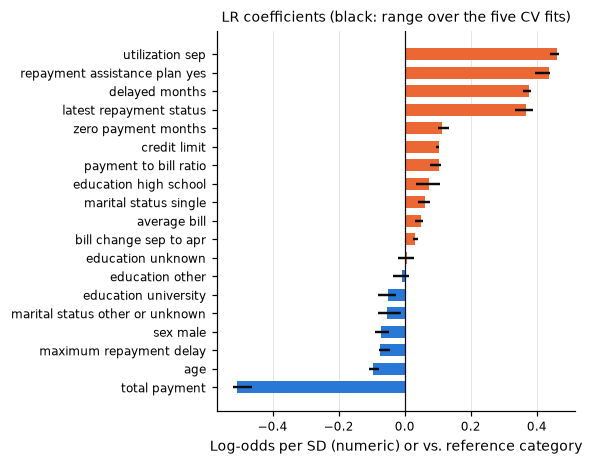

,coefficient,odds_ratio,fold_min,fold_max
total_payment_6m,-0.507,0.602,-0.520,-0.462
age,-0.095,0.909,-0.107,-0.079
maximum_repayment_delay_6m,-0.076,0.926,-0.078,-0.046
sex_male,-0.073,0.930,-0.091,-0.048
marital_status_other_or_unknown,-0.053,0.948,-0.081,-0.011
education_university,-0.052,0.950,-0.082,-0.025
education_other,-0.008,0.992,-0.034,0.012
education_unknown,0.006,1.006,-0.020,0.027
bill_change_sep_to_apr,0.030,1.030,0.025,0.039
average_bill_6m,0.049,1.050,0.030,0.056


In [19]:
coefficients = pd.Series(linear.sk_model_.coef_[0], index=logit_features)
fold_coefficients = pd.DataFrame(
    [clone(logit_model).fit(X_train.iloc[fit], y_train.iloc[fit]).named_steps["model"].coef_[0] for fit, _ in folds],
    columns=logit_features,
)
coefficient_table = pd.DataFrame({
    "coefficient": coefficients, "odds_ratio": np.exp(coefficients),
    "fold_min": fold_coefficients.min(), "fold_max": fold_coefficients.max(),
}).sort_values("coefficient")
print(f"Intercept: {linear.sk_model_.intercept_[0]:.3f}")

fig, ax = plt.subplots(figsize=(5.4, 4.3))
positions = np.arange(len(coefficient_table))
ax.barh(positions, coefficient_table["coefficient"], height=0.65,
        color=np.where(coefficient_table["coefficient"] > 0, "#eb6834", "#2a78d6"))
ax.hlines(positions, coefficient_table["fold_min"], coefficient_table["fold_max"], color="#0b0b0b", lw=1.6)
ax.set_yticks(positions, [pretty(name) for name in coefficient_table.index])
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("Log-odds per SD (numeric) or vs. reference category")
ax.set_title("LR coefficients (black: range over the five CV fits)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
save_figure(fig, "logit_coefficients")
plt.show()
coefficient_table.round(3)

**Can we read the coefficients as effects?** Only conditionally on all other variables. Several predictors are
strongly correlated, and three coefficients have the opposite sign to the variable's own association with the
target:

In [20]:
marginal = pd.concat([X_train[numeric], y_train], axis=1).corr()[target].drop(target)
sign_check = pd.DataFrame({"marginal_correlation": marginal, "coefficient": coefficients.reindex(numeric)})
sign_check["sign_reversed"] = np.sign(sign_check["marginal_correlation"]) != np.sign(sign_check["coefficient"])
print("Correlation of maximum delay with delayed months:",
      round(X_train["maximum_repayment_delay_6m"].corr(X_train["delayed_months_6m"]), 2))
sign_check.round(3)

Correlation of maximum delay with delayed months: 0.83


,marginal_correlation,coefficient,sign_reversed
credit_limit,-0.120,0.105,True
age,-0.035,-0.095,False
latest_repayment_status,0.302,0.368,False
maximum_repayment_delay_6m,0.265,-0.076,True
delayed_months_6m,0.312,0.378,False
average_bill_6m,0.040,0.049,False
bill_change_sep_to_apr,0.050,0.030,False
total_payment_6m,-0.097,-0.507,False
payment_to_bill_ratio_6m,-0.138,0.104,True
zero_payment_months_6m,0.186,0.113,False


### Evaluate

In [21]:
evaluate_with_cv("Logistic regression", logit_model)

Logistic regression: t_acc = 0.47, t_bal = 0.22


,auc,brier,accuracy,balanced_accuracy,recall_1,recall_0
mean,0.761,0.137,0.814,0.695,0.624,0.767
std,0.008,0.003,0.008,0.009,0.016,0.009


**Observations.**
* Utilization, the assistance plan, delayed months and repayment status raise the risk; total payment (log)
  lowers it. The signs are stable over the five CV refits.
* `maximum_repayment_delay_6m`, `credit_limit` and `payment_to_bill_ratio_6m` reverse their marginal sign:
  collinearity, not a real protective effect.
* The model is linear in the repayment-status codes, so it puts the undocumented codes -2, -1 and 0 on a line.

## 4. Explainable Boosting Machine

The EBM gets the raw columns: it bins numerical variables itself and treats the string columns as nominal, so
every original variable has one shape function. `interactions=0` keeps it purely additive.

### Train: choose the number of bins and leaf size with CV

EBM training is slow (about 5 minutes for this grid).

In [22]:
ebm_search = GridSearchCV(
    ExplainableBoostingClassifier(interactions=0, random_state=seed, n_jobs=n_jobs),
    {"max_bins": [32, 256, 1024], "min_samples_leaf": [4, 50]},
    scoring="roc_auc", cv=folds, refit=True, n_jobs=1,
).fit(X_train, y_train)
ebm = ebm_search.best_estimator_
ebm_params = ebm_search.best_params_
models["EBM"] = ebm
print("Selected:", ebm_params)
pd.DataFrame(ebm_search.cv_results_)[["param_max_bins", "param_min_samples_leaf", "mean_test_score",
                                      "std_test_score"]].sort_values("mean_test_score", ascending=False).round(4)

Selected: {'max_bins': 256, 'min_samples_leaf': 50}


,param_max_bins,param_min_samples_leaf,mean_test_score,std_test_score
3,256,50,0.7757,0.0089
5,1024,50,0.7756,0.0088
2,256,4,0.7756,0.0090
4,1024,4,0.7753,0.0088
1,32,50,0.7746,0.0083
0,32,4,0.7746,0.0083


CV AUC only varies between 0.7746 and 0.7757: the EBM is not sensitive to these settings.

### Global explanations

In 'Summary' the terms are sorted by mean absolute score; click a term to see its shape function.

In [23]:
ebm_global = ebm.explain_global(name="EBM")
show(ebm_global)

Static version of the eight most important shape functions for the report (band: ± one standard deviation over
the EBM's bagged fits; x-axes cover the central 99 % of the data).

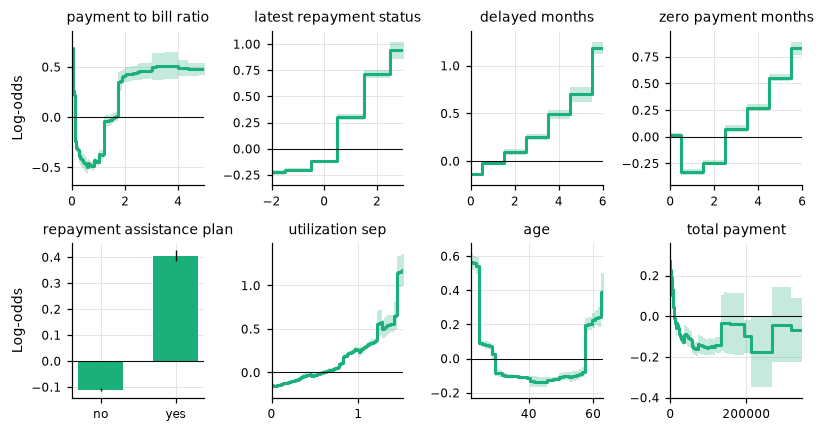

,mean_absolute_score
payment_to_bill_ratio_6m,0.338
latest_repayment_status,0.235
delayed_months_6m,0.183
zero_payment_months_6m,0.174
repayment_assistance_plan,0.173
utilization_sep,0.148
age,0.144
total_payment_6m,0.103
bill_change_sep_to_apr,0.065
maximum_repayment_delay_6m,0.055


In [24]:
ebm_importance = pd.Series(ebm.term_importances(), index=ebm.term_names_).sort_values(ascending=False)


def plot_ebm_term(ax, term_name):
    data = ebm_global.data(ebm.term_names_.index(term_name))
    names, scores = list(data["names"]), np.asarray(data["scores"])
    lower, upper = np.asarray(data["lower_bounds"]), np.asarray(data["upper_bounds"])
    color = model_colors["EBM"]
    if term_name in categorical:
        positions = np.arange(len(scores))
        ax.bar(positions, scores, color=color, width=0.6)
        ax.errorbar(positions, scores, yerr=[scores - lower, upper - scores], fmt="none", ecolor="#0b0b0b", lw=0.9)
        ax.set_xticks(positions, names)
    else:
        edges = np.asarray(names, dtype=float)
        ax.fill_between(edges, np.r_[lower, lower[-1]], np.r_[upper, upper[-1]], step="post", color=color,
                        alpha=0.25, lw=0)
        ax.step(edges, np.r_[scores, scores[-1]], where="post", color=color, lw=2)
        low, high = X_train[term_name].quantile([0.005, 0.995])
        ax.set_xlim(low, high)
        visible = (edges[1:] > low) & (edges[:-1] < high)
        span = upper[visible].max() - lower[visible].min()
        ax.set_ylim(lower[visible].min() - 0.08 * span, upper[visible].max() + 0.08 * span)
    ax.axhline(0, color="#0b0b0b", lw=0.7)
    ax.set_title(pretty(term_name))


fig, axes = plt.subplots(2, 4, figsize=(7.5, 4.0))
for ax, term in zip(axes.ravel(), ebm_importance.index[:8]):
    plot_ebm_term(ax, term)
for ax in axes[:, 0]:
    ax.set_ylabel("Log-odds")
fig.tight_layout()
save_figure(fig, "ebm_shapes")
plt.show()
ebm_importance.round(3).to_frame("mean_absolute_score")

### Evaluate

In [25]:
evaluate_with_cv("EBM", ebm)

EBM: t_acc = 0.49, t_bal = 0.23


,auc,brier,accuracy,balanced_accuracy,recall_1,recall_0
mean,0.776,0.134,0.817,0.705,0.624,0.787
std,0.010,0.003,0.006,0.008,0.011,0.008


### Editing the model: monotonize

As in the EBM lab, we can impose domain knowledge after training. More zero-payment months should not lower the
risk, but the learned shape dips at 1–2 months. We monotonize that term (increasing) inside each CV fold and
compare the CV AUC with the unedited model.

CV AUC (pooled out-of-fold): original 0.7756, monotonized 0.7728


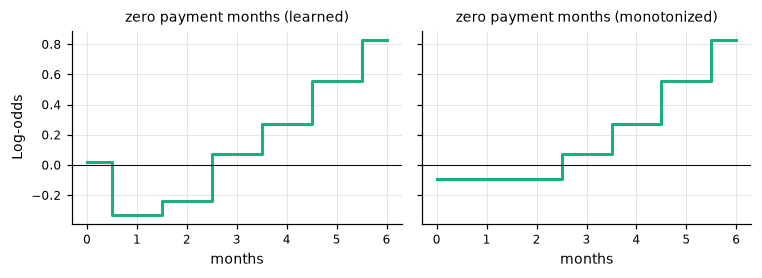

In [26]:
monotone_probabilities = np.zeros(len(y_train))
for fit_index, left_out_index in folds:
    fold_ebm = clone(ebm).fit(X_train.iloc[fit_index], y_train.iloc[fit_index])
    fold_ebm.monotonize("zero_payment_months_6m", increasing=True)
    monotone_probabilities[left_out_index] = fold_ebm.predict_proba(X_train.iloc[left_out_index])[:, 1]
print(f"CV AUC (pooled out-of-fold): original {roc_auc_score(y_train, oof['EBM']):.4f}, "
      f"monotonized {roc_auc_score(y_train, monotone_probabilities):.4f}")

ebm_monotone = clone(ebm).fit(X_train, y_train)
ebm_monotone.monotonize("zero_payment_months_6m", increasing=True)
fig, axes = plt.subplots(1, 2, figsize=(7, 2.6), sharey=True)
for ax, model, title in zip(axes, (ebm, ebm_monotone), ("learned", "monotonized")):
    index = model.term_names_.index("zero_payment_months_6m")
    ax.step(np.arange(7), model.term_scores_[index][1:8], where="mid", color=model_colors["EBM"], lw=2)
    ax.axhline(0, color="#0b0b0b", lw=0.7)
    ax.set(title=f"zero payment months ({title})", xlabel="months")
axes[0].set_ylabel("Log-odds")
fig.tight_layout()
plt.show()

**Observations.**
* Payment-to-bill ratio is the most important term and is **U-shaped**: paying almost nothing is risky, risk is
  lowest at ratios of about 0.5–1.2, and it rises again above about 1.7 (catch-up payments or tiny bills).
* Repayment status is flat over the non-positive codes and rises in steps from code 1.
* Zero-payment months: 1–2 months lower the risk, 3 or more raise it. Forcing this term to be increasing lowers
  the CV AUC (0.7756 -> 0.7728), so the dip is a real pattern in the data, not noise; we keep the learned model.
* Age is U-shaped (under 25 and over 57 are riskier); utilization jumps for over-limit accounts.

## 5. Comparison of the three models

### Reference models

A majority-class baseline (chance level) and an untuned gradient-boosting black box, to see what interpretability
costs. They do not replace the mandatory models.

In [27]:
baseline_model = DummyClassifier(strategy="prior").fit(X_train, y_train)
blackbox_model = Pipeline([("prep", clone(tree_encoder)),
                           ("model", HistGradientBoostingClassifier(random_state=seed))]).fit(X_train, y_train)
models["Majority baseline"] = baseline_model
models["Gradient boosting (black box)"] = blackbox_model
evaluate_with_cv("Majority baseline", baseline_model, choose_thresholds=False)
evaluate_with_cv("Gradient boosting (black box)", blackbox_model)
glassbox = ["Decision tree", "Logistic regression", "EBM"]
order = ["Majority baseline"] + glassbox + ["Gradient boosting (black box)"]

Majority baseline: t_acc = 0.50, t_bal = 0.50


Gradient boosting (black box): t_acc = 0.52, t_bal = 0.23


### Five-fold CV summary (Table 1 of the report)

In [28]:
fold_metrics_frame = pd.DataFrame(fold_metrics)
cv_summary = fold_metrics_frame.groupby("model").agg(["mean", "std"]).drop(columns="fold").loc[order]
threshold_columns = pd.DataFrame(thresholds).T.loc[order]
threshold_columns.columns = pd.MultiIndex.from_product([threshold_columns.columns, ["value"]])
cv_summary = cv_summary.join(threshold_columns)
cv_summary.round(3)

auc         brier        accuracy        balanced_accuracy        recall_1        recall_0        t_acc t_bal
                                mean    std   mean    std     mean    std              mean    std     mean    std     mean    std value value
model                                                                                                                                         
Majority baseline              0.500  0.000  0.167  0.000    0.788  0.000             0.500  0.000    0.000  0.000    1.000  0.000  0.50  0.50
Decision tree                  0.752  0.011  0.139  0.003    0.812  0.005             0.692  0.009    0.650  0.012    0.735  0.019  0.49  0.18
Logistic regression            0.761  0.008  0.137  0.003    0.814  0.008             0.695  0.009    0.624  0.016    0.767  0.009  0.47  0.22
EBM                            0.776  0.010  0.134  0.003    0.817  0.006             0.705  0.008    0.624  0.011    0.787  0.008  0.49  0.23
Gradient boosting (black box)  0.768  0.012  0.136  0.004    0.815  0.006             0.701  0.013    0.617  0.019    0.785  0.010  0.52  0.23

All models use the same folds, so we can compare them fold by fold:

In [29]:
auc_by_fold = fold_metrics_frame.pivot(index="fold", columns="model", values="auc")
for first, second in [("EBM", "Logistic regression"), ("EBM", "Decision tree"),
                      ("Logistic regression", "Decision tree"), ("Gradient boosting (black box)", "EBM")]:
    difference = auc_by_fold[first] - auc_by_fold[second]
    print(f"AUC {first} - {second}: mean {difference.mean():+.4f}, sd {difference.std():.4f}, "
          f"positive in {(difference > 0).sum()}/5 folds")

AUC EBM - Logistic regression: mean +0.0143, sd 0.0040, positive in 5/5 folds
AUC EBM - Decision tree: mean +0.0232, sd 0.0066, positive in 5/5 folds
AUC Logistic regression - Decision tree: mean +0.0090, sd 0.0051, positive in 5/5 folds
AUC Gradient boosting (black box) - EBM: mean -0.0074, sd 0.0022, positive in 0/5 folds


### Confirmation on the validation set

Models fitted on the training set, thresholds fixed from CV. This is the only use of the validation labels.

In [30]:
validation_probabilities = {name: models[name].predict_proba(X_validation)[:, 1] for name in order}
validation_summary = pd.DataFrame({name: classification_metrics(y_validation.to_numpy(), validation_probabilities[name],
                                                          **thresholds[name]) for name in order}).T
validation_decisions = {name: (validation_probabilities[name] >= thresholds[name]["t_bal"]).astype(int) for name in glassbox}
validation_summary["flagged"] = pd.Series({name: validation_decisions[name].mean() for name in glassbox})
validation_summary.round(3)

,auc,brier,accuracy,balanced_accuracy,recall_1,recall_0,flagged
Majority baseline,0.500,0.167,0.788,0.500,0.000,1.000,NaN
Decision tree,0.749,0.138,0.814,0.688,0.597,0.779,0.301
Logistic regression,0.766,0.135,0.820,0.690,0.607,0.773,0.307
EBM,0.775,0.133,0.825,0.696,0.597,0.795,0.288
Gradient boosting (black box),0.765,0.135,0.821,0.691,0.589,0.793,NaN


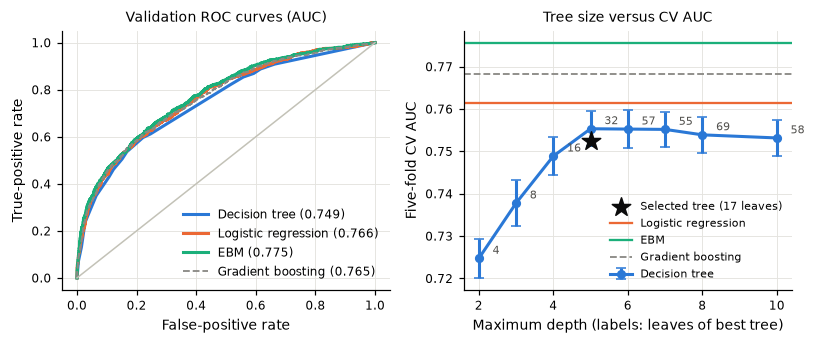

In [31]:
fig, (ax_roc, ax_depth) = plt.subplots(1, 2, figsize=(7.5, 3.2))
for name in glassbox + ["Gradient boosting (black box)"]:
    fpr, tpr, _ = roc_curve(y_validation, validation_probabilities[name])
    is_glassbox = name in glassbox
    ax_roc.plot(fpr, tpr, color=model_colors.get(name, reference_color), lw=2 if is_glassbox else 1.2,
                ls="-" if is_glassbox else "--",
                label=f"{name if is_glassbox else 'Gradient boosting'} "
                      f"({roc_auc_score(y_validation, validation_probabilities[name]):.3f})")
ax_roc.plot([0, 1], [0, 1], color="#c3c2b7", lw=1)
ax_roc.set(xlabel="False-positive rate", ylabel="True-positive rate", title="Validation ROC curves (AUC)")
ax_roc.legend(loc="lower right", frameon=False)

depths = by_depth["param_model__max_depth"].astype(int).to_numpy()
ax_depth.errorbar(depths, by_depth["mean_test_score"], yerr=by_depth["std_test_score"] / np.sqrt(5),
                  color=model_colors["Decision tree"], marker="o", ms=5, lw=2, capsize=3, label="Decision tree")
for depth, auc in zip(depths, by_depth["mean_test_score"]):
    ax_depth.annotate(f"{leaves_by_depth[depth]}", (depth, auc), textcoords="offset points", xytext=(9, 3),
                      ha="left", fontsize=7, color="#52514e")
ax_depth.scatter([tree_params["model__max_depth"]], [tree_results.loc[tree_search.best_index_, "mean_test_score"]],
                 marker="*", s=160, color="#0b0b0b", zorder=4, label=f"Selected tree ({tree_sk.get_n_leaves()} leaves)")
for name in ["Logistic regression", "EBM"]:
    ax_depth.axhline(cv_summary.loc[name, ("auc", "mean")], color=model_colors[name], lw=1.5, label=name)
ax_depth.axhline(cv_summary.loc["Gradient boosting (black box)", ("auc", "mean")], color=reference_color,
                 lw=1.2, ls="--", label="Gradient boosting")
ax_depth.set(xlabel="Maximum depth (labels: leaves of best tree)", ylabel="Five-fold CV AUC",
             title="Tree size versus CV AUC")
ax_depth.legend(frameon=False, loc="lower right", fontsize=7)
fig.tight_layout()
save_figure(fig, "performance_overview")
plt.show()

Confusion matrices at `t_bal` and agreement between the models.

In [32]:
for name in glassbox:
    print(name, f"(t_bal = {thresholds[name]['t_bal']:.2f})")
    print(confusion_matrix(y_validation, validation_decisions[name]))

agreement = []
for i, first in enumerate(glassbox):
    for second in glassbox[i + 1:]:
        agreement.append({"pair": f"{first} vs {second}",
                          "agreement": np.mean(validation_decisions[first] == validation_decisions[second]),
                          "cohen_kappa": cohen_kappa_score(validation_decisions[first], validation_decisions[second])})
all_agree = np.mean((validation_decisions["Decision tree"] == validation_decisions["Logistic regression"])
                    & (validation_decisions["Logistic regression"] == validation_decisions["EBM"]))
print(f"All three models agree on {all_agree:.1%} of validation instances.")
pd.DataFrame(agreement).round(3)

Decision tree (t_bal = 0.18)
[[3067  872]
 [ 428  633]]
Logistic regression (t_bal = 0.22)
[[3046  893]
 [ 417  644]]
EBM (t_bal = 0.23)
[[3131  808]
 [ 428  633]]
All three models agree on 87.1% of validation instances.


,pair,agreement,cohen_kappa
0,Decision tree vs Logistic regression,0.896,0.755
1,Decision tree vs EBM,0.922,0.812
2,Logistic regression vs EBM,0.923,0.816


### Global comparison: permutation importance

The native importances (impurity, coefficients, mean absolute score) measure different things. Permutation
importance measures every model the same way: the drop in validation AUC when one original variable is shuffled.

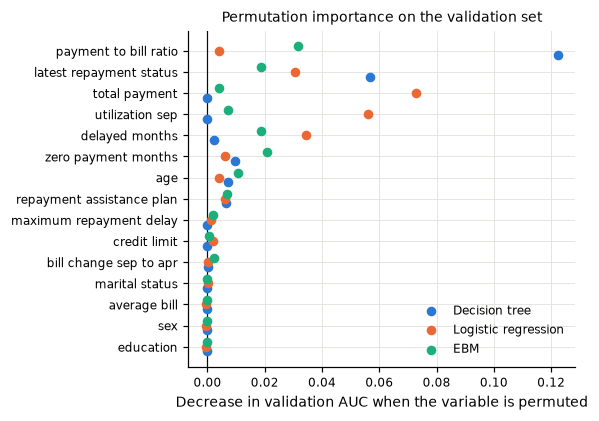

Spearman rank correlation between the models' importances:


,Decision tree,Logistic regression,EBM
Decision tree,1.00,0.36,0.85
Logistic regression,0.36,1.00,0.73
EBM,0.85,0.73,1.00


,Decision tree,Logistic regression,EBM
payment_to_bill_ratio_6m,0.1223,0.0039,0.0315
zero_payment_months_6m,0.0095,0.0062,0.0208
latest_repayment_status,0.0567,0.0306,0.0188
delayed_months_6m,0.0022,0.0343,0.0186
age,0.0071,0.0040,0.0107
utilization_sep,0.0000,0.0560,0.0073
repayment_assistance_plan,0.0065,0.0061,0.0069
total_payment_6m,0.0000,0.0729,0.0039
bill_change_sep_to_apr,0.0002,0.0000,0.0022
maximum_repayment_delay_6m,0.0000,0.0012,0.0018


In [33]:
permutation = pd.DataFrame({
    name: permutation_importance(models[name], X_validation, y_validation, scoring="roc_auc", n_repeats=10,
                                 random_state=seed, n_jobs=1).importances_mean
    for name in glassbox
}, index=X_validation.columns)
permutation = permutation.loc[permutation.mean(axis=1).sort_values().index]

fig, ax = plt.subplots(figsize=(5.4, 3.9))
positions = np.arange(len(permutation))
for offset, name in zip((-0.22, 0, 0.22), glassbox):
    ax.scatter(permutation[name], positions + offset, color=model_colors[name], s=28, label=name, zorder=3)
ax.set_yticks(positions, [pretty(name) for name in permutation.index])
ax.axvline(0, color="#0b0b0b", lw=0.8)
ax.set_xlabel("Decrease in validation AUC when the variable is permuted")
ax.legend(frameon=False, loc="lower right")
ax.set_title("Permutation importance on the validation set")
fig.tight_layout()
save_figure(fig, "permutation_importance")
plt.show()

print("Spearman rank correlation between the models' importances:")
display(permutation.corr(method="spearman").round(2))
permutation.sort_values("EBM", ascending=False).round(4)

### Same variable, three explanations

For each model, set the variable to each grid value in 1,000 training rows and average the log-odds
(partial dependence on the log-odds scale, centred). For LR and the EBM this is exactly their additive effect.

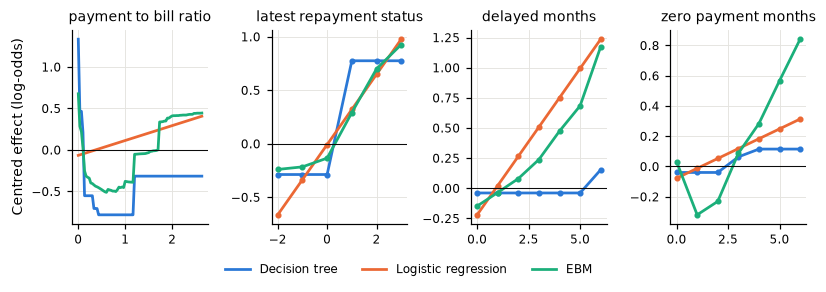

In [34]:
reference_rows = X_train.sample(1000, random_state=seed)


def effect_curve(model, feature, grid):
    baseline = logit(model.predict_proba(reference_rows)[:, 1]).mean()
    curve = []
    for value in grid:
        modified = reference_rows.copy()
        modified[feature] = value
        curve.append(logit(model.predict_proba(modified)[:, 1]).mean() - baseline)
    return np.asarray(curve)


compare_features = [f for f in ebm_importance.index if f in numeric][:4]
fig, axes = plt.subplots(1, 4, figsize=(7.5, 2.6))
for ax, feature in zip(axes, compare_features):
    low, high = X_train[feature].quantile([0.01, 0.99])
    discrete = pd.api.types.is_integer_dtype(X[feature]) and X_train[feature].nunique() <= 15
    grid = np.arange(int(low), int(high) + 1) if discrete else np.linspace(low, high, 80)
    for name in glassbox:
        ax.plot(grid, effect_curve(models[name], feature, grid), color=model_colors[name], lw=1.8,
                marker="o" if discrete else None, ms=3, label=name)
    ax.axhline(0, color="#0b0b0b", lw=0.7)
    ax.set_title(pretty(feature))
axes[0].set_ylabel("Centred effect (log-odds)")
fig.legend(*axes[0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.02))
fig.tight_layout(rect=(0, 0.07, 1, 1))
save_figure(fig, "effect_comparison")
plt.show()

### Local explanations: the same instances for all three models

Four validation clients, chosen by fixed rules on the `t_bal` decisions:

* **A**: actual class 0, all three models correct (the most typical one: EBM probability closest to the median);
* **B**: actual class 1, all three models correct (same criterion);
* **C**: actual class 1 where the models disagree most (largest spread of log-odds);
* **D**: actual class 0 where the models disagree most.

In [35]:
validation_frame = pd.DataFrame({name: validation_probabilities[name] for name in glassbox}, index=X_validation.index)
decision_frame = pd.DataFrame(validation_decisions, index=X_validation.index)
unanimous = decision_frame.nunique(axis=1) == 1
logit_spread = logit(validation_frame).std(axis=1)


def most_typical(mask):
    candidates = validation_frame.loc[mask, "EBM"]
    return (candidates - candidates.median()).abs().idxmin()


case_index = {
    "A": most_typical(unanimous & (y_validation == 0) & (decision_frame["EBM"] == 0)),
    "B": most_typical(unanimous & (y_validation == 1) & (decision_frame["EBM"] == 1)),
    "C": logit_spread[~unanimous & (y_validation == 1)].idxmax(),
    "D": logit_spread[~unanimous & (y_validation == 0)].idxmax(),
}
rows = list(case_index.values())
local_X = X_validation.loc[rows]
local_y = y_validation.loc[rows]
local_cases = pd.DataFrame({
    "row_id": train.loc[rows, "row_id"].to_numpy(),
    "actual": local_y.to_numpy(),
    **{f"p_{name}": validation_frame.loc[rows, name].round(3).to_numpy() for name in glassbox},
    **{f"pred_{name}": decision_frame.loc[rows, name].to_numpy() for name in glassbox},
}, index=list(case_index))
display(local_cases)
local_X.set_index(local_cases.index).T

,row_id,actual,p_Decision tree,p_Logistic regression,p_EBM,pred_Decision tree,pred_Logistic regression,pred_EBM
A,CR26-119951,0,0.118,0.134,0.096,0,0,0
B,CR26-109661,1,0.505,0.469,0.533,1,1,1
C,CR26-115142,1,0.154,0.500,0.550,0,1,1
D,CR26-125976,0,0.062,0.387,0.278,0,1,1


,A,B,C,D
credit_limit,100000,110000,20000,30000
sex,female,female,female,female
education,university,university,high_school,high_school
marital_status,single,single,single,married
age,23,25,31,42
latest_repayment_status,0,2,1,0
maximum_repayment_delay_6m,0,2,3,0
delayed_months_6m,0,1,4,0
average_bill_6m,2200,94200,-400,29100
bill_change_sep_to_apr,11300,28700,2000,46000


The InterpretML local views for the same four clients (in order A, B, C, D).

In [36]:
ebm_local = ebm.explain_local(local_X, local_y, name="EBM")
show(ebm_local)

In [37]:
local_X_logit = pd.DataFrame(logit_model.named_steps["prep"].transform(local_X), columns=logit_features)
linear_local = linear.explain_local(local_X_logit, local_y, name="Logistic regression")
show(linear_local)

In [38]:
local_X_tree = pd.DataFrame(tree_model.named_steps["prep"].transform(local_X), columns=tree_features)
tree_local = tree.explain_local(local_X_tree, local_y, name="Decision tree")
show(tree_local)

To compare the three models on one scale, we decompose each prediction into log-odds contributions per original
variable:
* EBM: the shape-function values (`eval_terms`);
* LR: coefficient × standardized value (relative to an average client in the reference categories);
* tree: the change in node log-odds produced by each split on the decision path.

In all three cases, base value + contributions = the model's log-odds.

Base log-odds: {'Decision tree': -1.312, 'Logistic regression': -1.629, 'EBM': -1.575}


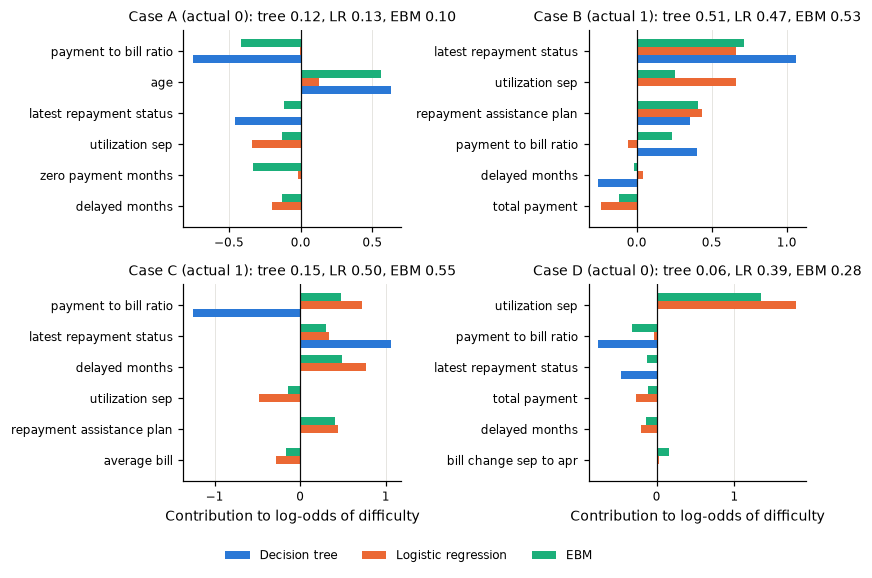

Case A


,Decision tree,Logistic regression,EBM
payment_to_bill_ratio_6m,-0.749,-0.004,-0.416
age,0.632,0.129,0.559
latest_repayment_status,-0.461,0.006,-0.119
utilization_sep,0.000,-0.342,-0.131
zero_payment_months_6m,0.000,-0.016,-0.331
delayed_months_6m,0.000,-0.202,-0.133


Case B


,Decision tree,Logistic regression,EBM
latest_repayment_status,1.064,0.663,0.715
utilization_sep,0.000,0.658,0.256
repayment_assistance_plan,0.354,0.438,0.406
payment_to_bill_ratio_6m,0.401,-0.056,0.235
delayed_months_6m,-0.256,0.040,-0.021
total_payment_6m,0.000,-0.242,-0.117


Case C


,Decision tree,Logistic regression,EBM
payment_to_bill_ratio_6m,-1.249,0.721,0.478
latest_repayment_status,1.064,0.334,0.306
delayed_months_6m,0.000,0.769,0.489
utilization_sep,0.000,-0.479,-0.146
repayment_assistance_plan,0.000,0.438,0.406
average_bill_6m,0.000,-0.278,-0.162


Case D


,Decision tree,Logistic regression,EBM
utilization_sep,0.000,1.796,1.339
payment_to_bill_ratio_6m,-0.749,-0.029,-0.319
latest_repayment_status,-0.461,0.006,-0.119
total_payment_6m,0.000,-0.271,-0.113
delayed_months_6m,0.000,-0.202,-0.133
bill_change_sep_to_apr,0.000,0.031,0.156


In [39]:
def tree_contributions(row):
    path = tree_sk.decision_path(tree_model.named_steps["prep"].transform(row)).indices
    node_logit = logit(node_risk)
    contributions = pd.Series(0.0, index=X.columns)
    for parent, child in zip(path[:-1], path[1:]):
        feature = original_feature(tree_features[tree_sk.tree_.feature[parent]])
        contributions[feature] += node_logit[child] - node_logit[parent]
    return contributions, node_logit[0]


def logit_contributions(row):
    encoded = logit_model.named_steps["prep"].transform(row)[0]
    terms = pd.Series(encoded * linear.sk_model_.coef_[0], index=logit_features)
    return terms.groupby(original_feature).sum().reindex(X.columns, fill_value=0.0), linear.sk_model_.intercept_[0]


def ebm_contributions(row):
    return pd.Series(ebm.eval_terms(row)[0], index=ebm.term_names_).reindex(X.columns), float(ebm.intercept_[0])


contribution_functions = {"Decision tree": tree_contributions, "Logistic regression": logit_contributions,
                          "EBM": ebm_contributions}
local_contributions = {}
for case, index in case_index.items():
    row = X_validation.loc[[index]]
    local_contributions[case] = pd.DataFrame({name: contribution_functions[name](row)[0] for name in glassbox})
print("Base log-odds:", {name: round(float(contribution_functions[name](local_X.iloc[[0]])[1]), 3)
                         for name in glassbox})

fig, axes = plt.subplots(2, 2, figsize=(7.5, 5.2))
for ax, (case, contributions) in zip(axes.ravel(), local_contributions.items()):
    top = contributions.abs().max(axis=1).sort_values(ascending=False).index[:6][::-1]
    positions = np.arange(len(top))
    for offset, name in zip((-0.26, 0, 0.26), glassbox):
        ax.barh(positions + offset, contributions.loc[top, name], height=0.24, color=model_colors[name],
                label=name)
    ax.set_yticks(positions, [pretty(feature) for feature in top])
    ax.axvline(0, color="#0b0b0b", lw=0.8)
    info = local_cases.loc[case]
    probabilities = ", ".join(f"{short} {info[f'p_{name}']:.2f}"
                              for short, name in zip(("tree", "LR", "EBM"), glassbox))
    ax.set_title(f"Case {case} (actual {info['actual']}): {probabilities}")
    ax.grid(axis="y", visible=False)
for ax in axes[1]:
    ax.set_xlabel("Contribution to log-odds of difficulty")
# One shared legend below the panels, so it never covers a bar.
fig.legend(*axes[0, 0].get_legend_handles_labels(), loc="lower center", ncol=3, frameon=False,
           bbox_to_anchor=(0.5, -0.01))
fig.tight_layout(rect=(0, 0.05, 1, 1))
save_figure(fig, "local_comparison")
plt.show()

for case in case_index:
    print(f"Case {case}")
    display(local_contributions[case].loc[local_contributions[case].abs().max(axis=1)
                                          .sort_values(ascending=False).index[:6]].round(3))

**Observations.**
* **A** and **B**: the models agree on the outcome and mostly on the reasons (repayment status and the plan
  dominate case B in all three). In A, the tree and the EBM both penalise the client's young age; LR, linear in
  age, barely does.
* **C** (actual difficulty): payment-to-bill ratio 4.39 on a negative bill. The tree treats a high ratio as
  protective and misses the case; LR and the EBM read it as risk and flag the client.
* **D** (actual no difficulty): utilization 2.0 drives false alarms in LR and the EBM; the tree never uses
  utilization and is right.

### Subgroup audit by recorded sex

Descriptive error rates on the validation set at `t_bal`. Similar or different rates alone do not establish
fairness or unfairness (data dictionary).

In [40]:
audit = []
for name in glassbox:
    for group in sorted(X_validation["sex"].unique()):
        mask = (X_validation["sex"] == group).to_numpy()
        y_group, flagged = y_validation.to_numpy()[mask], validation_decisions[name][mask]
        audit.append({"model": name, "sex": group, "rows": int(mask.sum()), "observed_rate": y_group.mean(),
                      "flagged_rate": flagged.mean(), "TPR": recall_score(y_group, flagged),
                      "FPR": 1 - recall_score(y_group, flagged, pos_label=0)})
print("Permutation importance of sex (AUC drop):", permutation.loc["sex"].round(4).to_dict())
pd.DataFrame(audit).round(3)

Permutation importance of sex (AUC drop): {'Decision tree': 0.0, 'Logistic regression': -0.0005, 'EBM': -0.0003}


,model,sex,rows,observed_rate,flagged_rate,TPR,FPR
0,Decision tree,female,3029,0.205,0.297,0.604,0.218
1,Decision tree,male,1971,0.223,0.306,0.586,0.226
2,Logistic regression,female,3029,0.205,0.306,0.615,0.226
3,Logistic regression,male,1971,0.223,0.310,0.595,0.228
4,EBM,female,3029,0.205,0.286,0.605,0.203
5,EBM,male,1971,0.223,0.292,0.584,0.208


## 6. Final model and completed `test.csv`

The test set is graded on accuracy, so we submit the model with the highest five-fold CV accuracy at its
accuracy-maximizing threshold `t_acc`. It is refit with its selected settings on all labelled rows and the
column `predicted_class` is appended to `test.csv`.

In [41]:
final_name = cv_summary.loc[glassbox, ("accuracy", "mean")].idxmax()
final_threshold = thresholds[final_name]["t_acc"]
final_model = clone(models[final_name]).fit(X, y)
submission = test.copy()
submission["predicted_class"] = (final_model.predict_proba(X_test)[:, 1] >= final_threshold).astype(int)
submission.to_csv(data_dir / "test.csv", index=False)

print(f"Submitted model: {final_name} (threshold {final_threshold:.2f})")
print(f"Predicted positive share on test: {submission['predicted_class'].mean():.3f}")
for name in glassbox:
    other = (clone(models[name]).fit(X, y).predict_proba(X_test)[:, 1] >= thresholds[name]["t_acc"]).astype(int)
    print(f"Agreement with {name} at its t_acc: {np.mean(other == submission['predicted_class']):.3f}")
submission.head()

Submitted model: EBM (threshold 0.49)
Predicted positive share on test: 0.100
Agreement with Decision tree at its t_acc: 0.961


Agreement with Logistic regression at its t_acc: 0.970


Agreement with EBM at its t_acc: 1.000


,row_id,credit_limit,sex,education,marital_status,age,latest_repayment_status,maximum_repayment_delay_6m,delayed_months_6m,average_bill_6m,bill_change_sep_to_apr,total_payment_6m,payment_to_bill_ratio_6m,zero_payment_months_6m,utilization_sep,repayment_assistance_plan,predicted_class
0,CR26-128173,50000,male,graduate_school,single,25,0,0,0,27700,31600,21700,0.13,0,0.80,no,0
1,CR26-102911,280000,female,university,married,41,1,1,1,100,300,600,0.63,4,0.00,no,0
2,CR26-104960,420000,male,university,married,38,0,0,0,262500,108200,56200,0.04,0,0.70,no,0
3,CR26-123913,270000,male,university,single,44,0,0,0,247400,48900,56400,0.04,0,1.02,no,0
4,CR26-111750,120000,female,graduate_school,single,29,-1,0,0,1700,-2100,12000,1.20,0,0.00,yes,0
